In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from autorank import autorank, plot_stats, create_report, latex_table

from scipy import stats
import scikit_posthocs as sp
from scipy.stats import wilcoxon
from itertools import permutations

In [30]:
wavelet_2019 = pd.read_csv("../results/v2.5/wavelets_results_grouped_2019.csv")
max_2019 = pd.read_csv("../results/v2.5/max_results_grouped_2019.csv")
average_2019 = pd.read_csv("../results/v2.5/average_results_grouped_2019.csv")

In [31]:
model_results_2019 = pd.concat([wavelet_2019, max_2019, average_2019])

In [32]:
autorank_input_2019 = model_results_2019.pivot(index='seed', columns='wavelet_family', values='eer')
autorank_input_2019 = autorank_input_2019[['db4', 'db6', 'db8', 'db14', 'db16', 'db18', 'db24', 'db26', 'db28', 'db34', 'db36', 'db38', 'Average', 'Max']]
autorank_input_2019

wavelet_family,db4,db6,db8,db14,db16,db18,db24,db26,db28,db34,db36,db38,Average,Max
seed,,,,,,,,,,,,,,
32,0.082943,0.061863,0.062971,0.061163,0.081967,0.063248,0.067952,0.061456,0.069782,0.069913,0.077255,0.067299,0.070981,0.083105
42,0.059203,0.070787,0.086597,0.074591,0.076720,0.060847,0.069065,0.058192,0.062396,0.068282,0.074434,0.074825,0.062101,0.068806
49,0.072480,0.065961,0.061856,0.070289,0.081052,0.067983,0.075325,0.073525,0.070158,0.062540,0.054522,0.079807,0.072603,0.068113
51,0.060487,0.060095,0.061191,0.060367,0.067573,0.078722,0.062428,0.073148,0.058328,0.067186,0.083073,0.068525,0.064039,0.069605
69,0.067299,0.062939,0.060341,0.080060,0.069474,0.055067,0.064332,0.057512,0.075740,0.073011,0.070427,0.061033,0.073295,0.068145
73,0.070489,0.066153,0.066349,0.065715,0.070292,0.089931,0.063630,0.095173,0.072665,0.068345,0.079810,0.072164,0.067860,0.061709
81,0.067729,0.065938,0.062548,0.066599,0.066559,0.065123,0.073418,0.089340,0.065807,0.074202,0.078038,0.082128,0.062924,0.056420
91,0.058881,0.065376,0.060019,0.064439,0.065261,0.076377,0.063901,0.059434,0.065139,0.070427,0.073418,0.074102,0.068766,0.070827
99,0.068644,0.066207,0.064585,0.080491,0.064285,0.064723,0.065669,0.067998,0.065368,0.069759,0.071796,0.063655,0.065914,0.062240


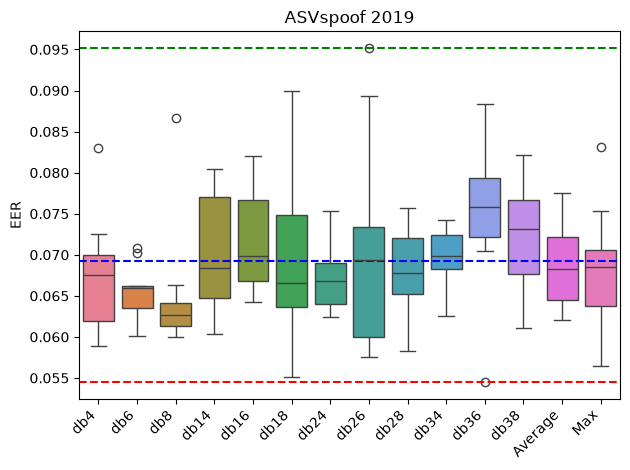

In [33]:
sns.boxplot(data=autorank_input_2019)
plt.title("ASVspoof 2019")

val_min = autorank_input_2019.min().min()
val_max = autorank_input_2019.max().max()
val_mean = autorank_input_2019.mean().mean()

plt.axhline(val_min, color='r', linestyle='--', label='Mínimo Global')
plt.axhline(val_mean, color='b', linestyle='--', label='Média Global')
plt.axhline(val_max, color='g', linestyle='--', label='Máximo Global')

plt.xticks(rotation=45, ha='right')

plt.xlabel("")
plt.ylabel("EER")
plt.tight_layout()
plt.show()

In [34]:
wavelet_2021= pd.read_csv("../results/v2.5/wavelets_results_grouped_2021.csv")
max_2021 = pd.read_csv("../results/v2.5/max_results_grouped_2021.csv")
average_2021= pd.read_csv("../results/v2.5/average_results_grouped_2021.csv")

In [35]:
model_results_2021 = pd.concat([wavelet_2021, max_2021, average_2021])

In [36]:
autorank_input_2021 = model_results_2021.pivot(index='seed', columns='wavelet_family', values='eer')
autorank_input_2021 = autorank_input_2021[['db4', 'db6', 'db8', 'db14', 'db16', 'db18', 'db24', 'db26', 'db28', 'db34', 'db36', 'db38', 'Average', 'Max']]
autorank_input_2021

wavelet_family,db4,db6,db8,db14,db16,db18,db24,db26,db28,db34,db36,db38,Average,Max
seed,,,,,,,,,,,,,,
32,0.161661,0.146481,0.147080,0.154835,0.150558,0.144795,0.146108,0.144157,0.156081,0.153632,0.157056,0.158140,0.139828,0.149577
42,0.148626,0.165927,0.174290,0.150827,0.171162,0.144158,0.153804,0.143616,0.149252,0.145181,0.147670,0.152458,0.144482,0.151421
49,0.160689,0.145132,0.166051,0.151366,0.159492,0.156950,0.150336,0.150127,0.150172,0.143890,0.143292,0.167354,0.146332,0.142815
51,0.152883,0.152636,0.140276,0.137871,0.146462,0.149523,0.142189,0.159992,0.153635,0.174561,0.193421,0.142803,0.142802,0.147517
69,0.143893,0.149422,0.141666,0.148331,0.148435,0.143507,0.144437,0.141074,0.151801,0.158031,0.156731,0.143073,0.154185,0.150239
73,0.142771,0.143291,0.143654,0.152233,0.151041,0.169489,0.141000,0.162414,0.159968,0.150845,0.147670,0.149693,0.143346,0.149310
81,0.143185,0.140527,0.144592,0.150655,0.146976,0.145570,0.152505,0.154513,0.156090,0.148669,0.185672,0.166768,0.144747,0.149947
91,0.150111,0.143987,0.149136,0.148872,0.146056,0.149577,0.143723,0.153866,0.144807,0.148277,0.151576,0.154887,0.152074,0.153966
99,0.147572,0.140743,0.149416,0.153544,0.143778,0.142098,0.160188,0.147137,0.175745,0.161379,0.150063,0.160732,0.140949,0.143128


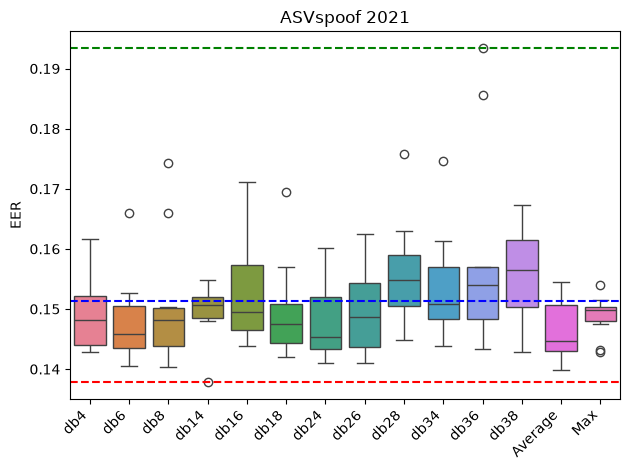

In [37]:
sns.boxplot(data=autorank_input_2021)
plt.title("ASVspoof 2021")

val_min = autorank_input_2021.min().min()
val_max = autorank_input_2021.max().max()
val_mean = autorank_input_2021.mean().mean()

plt.axhline(val_min, color='r', linestyle='--', label='Mínimo Global')
plt.axhline(val_mean, color='b', linestyle='--', label='Média Global')
plt.axhline(val_max, color='g', linestyle='--', label='Máximo Global')

plt.xticks(rotation=45, ha='right')

plt.xlabel("")
plt.ylabel("EER")
plt.tight_layout()
plt.show()

## AutoRank

### ASVspoof 2019

In [38]:
result_2019 = autorank(autorank_input_2019, alpha=0.05, verbose=False, order='ascending')
print(result_2019)

         meanrank    median       mad  ci_lower  ci_upper effect_size  \
db8           4.3  0.062674  0.001697  0.060019  0.086597         0.0   
db6           5.4  0.065950  0.001792  0.060095  0.070787   -1.265979   
db24          6.5  0.066810  0.002694  0.062428  0.075325   -1.239016   
db4           6.7  0.067514  0.003971  0.058881  0.082943   -1.069053   
db18          6.8  0.066553  0.004721  0.055067  0.089931   -0.737424   
Max           6.9  0.068475  0.004294   0.05642  0.083105   -1.198454   
db28          7.0  0.067795  0.003763  0.058328   0.07574   -1.183128   
db26          7.4  0.069417  0.008972  0.057512  0.095173   -0.704371   
db14          8.0  0.068444  0.006714  0.060367  0.080491   -0.794738   
Average       8.1  0.068313  0.004282  0.062101  0.077532   -1.167769   
db34          8.4  0.069836  0.002102   0.06254  0.074202   -2.528938   
db16          9.2  0.069883   0.00511  0.064285  0.081967   -1.277025   
db38          9.4  0.073133  0.005222  0.061033  0.

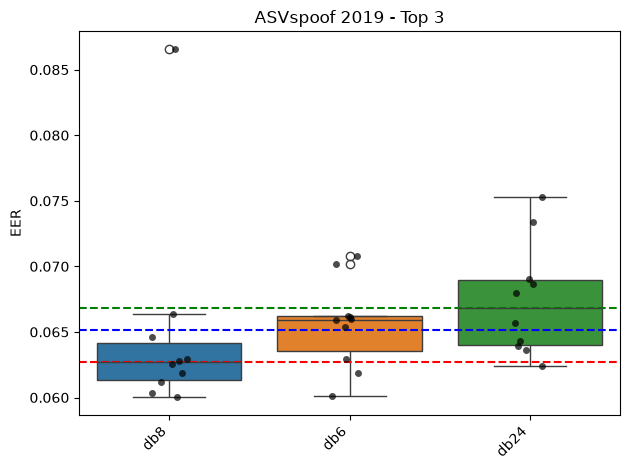

In [ ]:
autorank_2019_ranking = result_2019[0]
top_3_results_ranking = autorank_2019_ranking[:3]

top_3_results = autorank_input_2019[top_3_results_ranking.index]

sns.boxplot(data=top_3_results)
sns.stripplot(data=top_3_results, color='black', alpha=0.7)
plt.title("ASVspoof 2019 - Top 3")

val_min = top_3_results_ranking["median"].min().min()
val_max = top_3_results_ranking["median"].max().max()
val_mean = top_3_results_ranking["median"].mean().mean()

plt.axhline(val_min, color='r', linestyle='--', label='Mínimo Global')
plt.axhline(val_mean, color='b', linestyle='--', label='Média Global')
plt.axhline(val_max, color='g', linestyle='--', label='Máximo Global')

plt.xticks(rotation=45, ha='right')

plt.xlabel("")
plt.ylabel("EER")
plt.tight_layout()
plt.show()

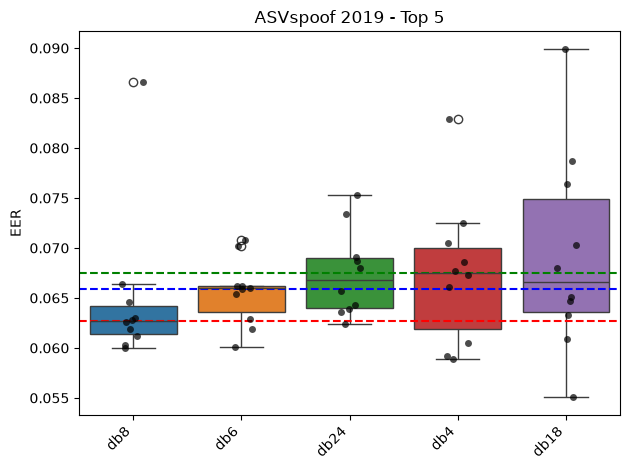

In [90]:
autorank_2019_ranking = result_2019[0]
top_5_results_ranking = autorank_2019_ranking[:5]
top_5_results = autorank_input_2019[top_5_results_ranking.index]

sns.boxplot(data=top_5_results)
sns.stripplot(data=top_5_results, color='black', alpha=0.7)
plt.title("ASVspoof 2019 - Top 5")

val_min = top_5_results_ranking["median"].min().min()
val_max = top_5_results_ranking["median"].max().max()
val_mean = top_5_results_ranking["median"].mean().mean()

plt.axhline(val_min, color='r', linestyle='--', label='Mínimo Global')
plt.axhline(val_mean, color='b', linestyle='--', label='Média Global')
plt.axhline(val_max, color='g', linestyle='--', label='Máximo Global')

plt.xticks(rotation=45, ha='right')

plt.xlabel("")
plt.ylabel("EER")
plt.tight_layout()
plt.show()

In [42]:
create_report(result_2019)

The statistical analysis was conducted for 14 populations with 10 paired samples.
The family-wise significance level of the tests is alpha=0.050.
We rejected the null hypothesis that the population is normal for the population db28 (p=0.000). Therefore, we assume that not all populations are normal.
Because we have more than two populations and the populations and one of them is not normal, we use the non-parametric Friedman test as omnibus test to determine if there are any significant differences between the median values of the populations. We use the post-hoc Nemenyi test to infer which differences are significant. We report the median (MD), the median absolute deviation (MAD) and the mean rank (MR) among all populations over the samples. Differences between populations are significant, if the difference of the mean rank is greater than the critical distance CD=6.274 of the Nemenyi test.
We failed to reject the null hypothesis (p=0.071) of the Friedman test that there is no differe

In [43]:
latex_table(result_2019)

\begin{table}[h]
\centering
\begin{tabular}{lrrll}
\toprule
 & MR & MED & MAD & CI \\
\midrule
db8 & 4.300 & 0.063 & 0.002 & [0.060, 0.087] \\
db6 & 5.400 & 0.066 & 0.002 & [0.060, 0.071] \\
db24 & 6.500 & 0.067 & 0.003 & [0.062, 0.075] \\
db4 & 6.700 & 0.068 & 0.004 & [0.059, 0.083] \\
db18 & 6.800 & 0.067 & 0.005 & [0.055, 0.090] \\
Max & 6.900 & 0.068 & 0.004 & [0.056, 0.083] \\
db28 & 7.000 & 0.068 & 0.004 & [0.058, 0.076] \\
db26 & 7.400 & 0.069 & 0.009 & [0.058, 0.095] \\
db14 & 8.000 & 0.068 & 0.007 & [0.060, 0.080] \\
Average & 8.100 & 0.068 & 0.004 & [0.062, 0.078] \\
db34 & 8.400 & 0.070 & 0.002 & [0.063, 0.074] \\
db16 & 9.200 & 0.070 & 0.005 & [0.064, 0.082] \\
db38 & 9.400 & 0.073 & 0.005 & [0.061, 0.082] \\
db36 & 10.900 & 0.076 & 0.004 & [0.055, 0.088] \\
\bottomrule
\end{tabular}
\caption{Summary of populations}
\label{tbl:stat_results}
\end{table}


<Axes: >

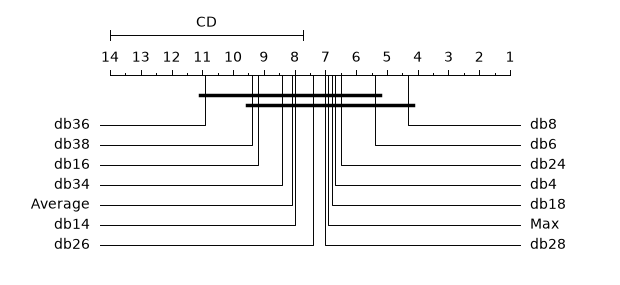

In [44]:
plot_stats(result_2019, allow_insignificant=True)

In [45]:
bayesian_result_2019 = autorank(
    autorank_input_2019, 
    alpha=0.05, 
    approach='bayesian', 
    rope=0.001,
    verbose=False, 
    order='ascending'
)

         meanrank    median       mad  ci_lower  ci_upper effect_size  \
db8           4.3  0.062674  0.001697  0.060019  0.086597         0.0   
db6           5.4  0.065950  0.001792  0.060095  0.070787   -1.265979   
db18          6.8  0.066553  0.004721  0.055067  0.089931   -0.737424   
db24          6.5  0.066810  0.002694  0.062428  0.075325   -1.239016   
db4           6.7  0.067514  0.003971  0.058881  0.082943   -1.069053   
db28          7.0  0.067795  0.003763  0.058328   0.07574   -1.183128   
Average       8.1  0.068313  0.004282  0.062101  0.077532   -1.167769   
db14          8.0  0.068444  0.006714  0.060367  0.080491   -0.794738   
Max           6.9  0.068475  0.004294   0.05642  0.083105   -1.198454   
db26          7.4  0.069417  0.008972  0.057512  0.095173   -0.704371   
db34          8.4  0.069836  0.002102   0.06254  0.074202   -2.528938   
db16          9.2  0.069883   0.00511  0.064285  0.081967   -1.277025   
db38          9.4  0.073133  0.005222  0.061033  0.

In [46]:
create_report(bayesian_result_2019)

The statistical analysis was conducted for 14 populations with 10 paired samples.
The family-wise significance level of the tests is alpha=0.050.
We rejected the null hypothesis that the population is normal for the population db28 (p=0.000). Therefore, we assume that not all populations are normal.
We used a bayesian signed rank test to determine differences between the mean values of the populations and report the median (MD) and the median absolute deviation (MAD) for each population. We distinguish between populations being pair-wise smaller, equal, or larger and make a decision for one of these cases if we estimate that the posterior probability is at least alpha=0.050.
We used the effect size to define the region of practical equivalence (ROPE) around the median dynamically as 0.001*gamma.
We found significant and practically relevant differences between the populations db8 (MD=0.063+-0.013, MAD=0.002), db6 (MD=0.066+-0.005, MAD=0.002), db18 (MD=0.067+-0.017, MAD=0.005), db24 (MD

### ASVspoof 2021

In [47]:
result_2021 = autorank(autorank_input_2021, alpha=0.05, verbose=False, order='ascending')
print(result_2021)

         meanrank      mean       std  ci_lower  ci_upper effect_size  \
db6           5.4  0.147902  0.007531  0.138594  0.157211         0.0   
db24          5.6  0.147748  0.006217  0.140063  0.155432    0.022372   
Average       5.6  0.146331  0.005385  0.139675  0.152987    0.240049   
db8           6.5  0.150650  0.010988  0.137068  0.164232   -0.291745   
db18          6.6  0.149687  0.008263  0.139474    0.1599   -0.225784   
db26          6.6  0.150019  0.007432  0.140833  0.159205   -0.282922   
db4           7.0  0.149555  0.006948  0.140967  0.158143   -0.228111   
Max           7.2  0.148831  0.003496   0.14451  0.153152   -0.158203   
db14          7.5  0.149661  0.004686  0.143869  0.155453   -0.280397   
db34          8.4  0.153517  0.009148  0.142209  0.164825   -0.670142   
db16          8.5  0.153511  0.010229  0.140867  0.166154   -0.624423   
db36          9.6  0.158945  0.016836  0.138135  0.179754   -0.846728   
db28         10.1  0.156056  0.008710   0.14529  0.

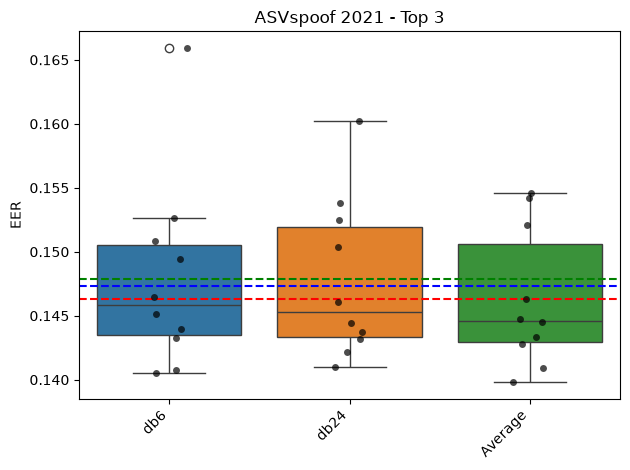

In [93]:
autorank_2021_ranking = result_2021[0]
top_3_results_ranking = autorank_2021_ranking[:3]

top_3_results = autorank_input_2021[top_3_results_ranking.index]

sns.boxplot(data=top_3_results)
sns.stripplot(data=top_3_results, color='black', alpha=0.7)
plt.title("ASVspoof 2021 - Top 3")

val_min = top_3_results_ranking["mean"].min().min()
val_max = top_3_results_ranking["mean"].max().max()
val_mean = top_3_results_ranking["mean"].mean().mean()

plt.axhline(val_min, color='r', linestyle='--', label='Mínimo Global')
plt.axhline(val_mean, color='b', linestyle='--', label='Média Global')
plt.axhline(val_max, color='g', linestyle='--', label='Máximo Global')

plt.xticks(rotation=45, ha='right')

plt.xlabel("")
plt.ylabel("EER")
plt.tight_layout()
plt.show()

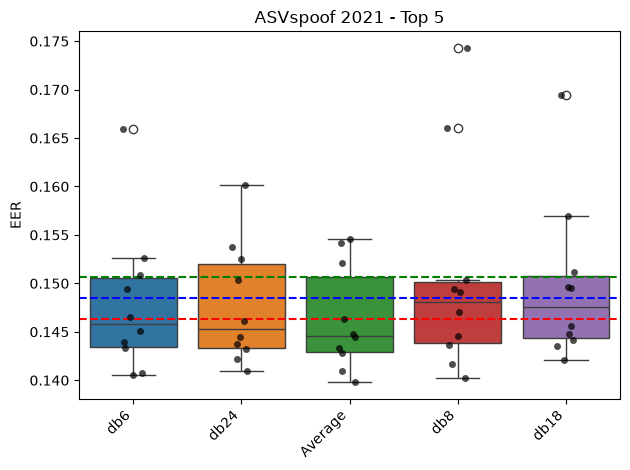

In [95]:
autorank_2021_ranking = result_2021[0]
top_5_results_ranking = autorank_2021_ranking[:5]

top_5_results = autorank_input_2021[top_5_results_ranking.index]

sns.boxplot(data=top_5_results)
sns.stripplot(data=top_5_results, color='black', alpha=0.7)
plt.title("ASVspoof 2021 - Top 5")

val_min = top_5_results_ranking["mean"].min().min()
val_max = top_5_results_ranking["mean"].max().max()
val_mean = top_5_results_ranking["mean"].mean().mean()

plt.axhline(val_min, color='r', linestyle='--', label='Mínimo Global')
plt.axhline(val_mean, color='b', linestyle='--', label='Média Global')
plt.axhline(val_max, color='g', linestyle='--', label='Máximo Global')

plt.xticks(rotation=45, ha='right')

plt.xlabel("")
plt.ylabel("EER")
plt.tight_layout()
plt.show()

In [50]:
create_report(result_2021)

The statistical analysis was conducted for 14 populations with 10 paired samples.
The family-wise significance level of the tests is alpha=0.050.
We failed to reject the null hypothesis that the population is normal for all populations (minimal observed p-value=0.006). Therefore, we assume that all populations are normal.
We applied Bartlett's test for homogeneity and reject the null hypothesis (p=0.002) that thedata is homoscedastic. Thus, we assume that our data is heteroscedastic.
Because we have more than two populations and the populations are normal but heteroscedastic, we use the non-parametric Friedman test as omnibus test to determine if there are any significant differences between the mean values of the populations. We use the post-hoc Nemenyi test to infer which differences are significant. We report the mean value (M), the standard deviation (SD) and the mean rank (MR) among all populations over the samples. Differences between populations are significant, if the differenc

In [51]:
latex_table(result_2021)

\begin{table}[h]
\centering
\begin{tabular}{lrrrl}
\toprule
 & MR & M & SD & CI \\
\midrule
db6 & 5.400 & 0.148 & 0.008 & [0.139, 0.157] \\
db24 & 5.600 & 0.148 & 0.006 & [0.140, 0.155] \\
Average & 5.600 & 0.146 & 0.005 & [0.140, 0.153] \\
db8 & 6.500 & 0.151 & 0.011 & [0.137, 0.164] \\
db18 & 6.600 & 0.150 & 0.008 & [0.139, 0.160] \\
db26 & 6.600 & 0.150 & 0.007 & [0.141, 0.159] \\
db4 & 7.000 & 0.150 & 0.007 & [0.141, 0.158] \\
Max & 7.200 & 0.149 & 0.003 & [0.145, 0.153] \\
db14 & 7.500 & 0.150 & 0.005 & [0.144, 0.155] \\
db34 & 8.400 & 0.154 & 0.009 & [0.142, 0.165] \\
db16 & 8.500 & 0.154 & 0.010 & [0.141, 0.166] \\
db36 & 9.600 & 0.159 & 0.017 & [0.138, 0.180] \\
db28 & 10.100 & 0.156 & 0.009 & [0.145, 0.167] \\
db38 & 10.400 & 0.156 & 0.009 & [0.145, 0.167] \\
\bottomrule
\end{tabular}
\caption{Summary of populations}
\label{tbl:stat_results}
\end{table}


<Axes: >

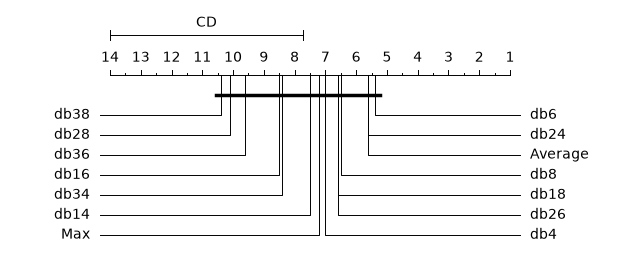

In [52]:
plot_stats(result_2021, allow_insignificant=True)

In [53]:
bayesian_result_2021 = autorank(
    autorank_input_2021, 
    alpha=0.05, 
    approach='bayesian', 
    rope=0.001,
    verbose=False, 
    order='ascending'
)

         meanrank      mean       std  ci_lower  ci_upper effect_size  \
Average       5.6  0.146331  0.005385  0.136432   0.15623         0.0   
db24          5.6  0.147748  0.006217  0.136318  0.159177   -0.243636   
db6           5.4  0.147902  0.007531  0.134058  0.161747   -0.240049   
Max           7.2  0.148831  0.003496  0.142404  0.155258   -0.550753   
db4           7.0  0.149555  0.006948  0.136781  0.162329   -0.518697   
db14          7.5  0.149661  0.004686  0.141046  0.158276    -0.65973   
db18          6.6  0.149687  0.008263  0.134497  0.164877   -0.481269   
db26          6.6  0.150019  0.007432  0.136357  0.163681   -0.568319   
db8           6.5  0.150650  0.010988  0.130449  0.170851   -0.499209   
db16          8.5  0.153511  0.010229  0.134706  0.172315   -0.878382   
db34          8.4  0.153517  0.009148  0.136699  0.170335   -0.957374   
db38         10.4  0.155773  0.008820  0.139559  0.171988   -1.292248   
db28         10.1  0.156056  0.008710  0.140044  0.

In [54]:
create_report(bayesian_result_2021)

The statistical analysis was conducted for 14 populations with 10 paired samples.
The family-wise significance level of the tests is alpha=0.050.
We failed to reject the null hypothesis that the population is normal for all populations (minimal observed p-value=0.006). Therefore, we assume that all populations are normal.
We used a bayesian signed rank test to determine differences between the mean values of the populations and report the mean value (M) and the standard deviation (SD) for each population. We distinguish between populations being pair-wise smaller, equal, or larger and make a decision for one of these cases if we estimate that the posterior probability is at least alpha=0.050.
We used the effect size to define the region of practical equivalence (ROPE) around the mean value dynamically as 0.001*d.
We found significant and practically relevant differences between the populations Average (M=0.146+-0.010, SD=0.005), db24 (M=0.148+-0.011, SD=0.006), db6 (M=0.148+-0.014, SD=

In [55]:
print(bayesian_result_2021.decision_matrix)

              Average          db24           db6           Max           db4  \
Average           NaN  inconclusive  inconclusive        larger  inconclusive   
db24     inconclusive           NaN  inconclusive  inconclusive  inconclusive   
db6      inconclusive  inconclusive           NaN  inconclusive  inconclusive   
Max           smaller  inconclusive  inconclusive           NaN  inconclusive   
db4      inconclusive  inconclusive  inconclusive  inconclusive           NaN   
db14     inconclusive  inconclusive  inconclusive  inconclusive  inconclusive   
db18     inconclusive  inconclusive  inconclusive  inconclusive  inconclusive   
db26     inconclusive  inconclusive  inconclusive  inconclusive  inconclusive   
db8      inconclusive  inconclusive  inconclusive  inconclusive  inconclusive   
db16          smaller  inconclusive       smaller  inconclusive  inconclusive   
db34          smaller  inconclusive  inconclusive  inconclusive  inconclusive   
db38          smaller       

In [56]:
print(bayesian_result_2021.posterior_matrix)

        Average                     db24                      db6  \
Average     NaN  (0.44166, 0.0, 0.55834)  (0.59078, 0.0, 0.40922)   
db24        NaN                      NaN  (0.29952, 0.0, 0.70048)   
db6         NaN                      NaN                      NaN   
Max         NaN                      NaN                      NaN   
db4         NaN                      NaN                      NaN   
db14        NaN                      NaN                      NaN   
db18        NaN                      NaN                      NaN   
db26        NaN                      NaN                      NaN   
db8         NaN                      NaN                      NaN   
db16        NaN                      NaN                      NaN   
db34        NaN                      NaN                      NaN   
db38        NaN                      NaN                      NaN   
db28        NaN                      NaN                      NaN   
db36        NaN                   

## Friedman Test

### ASVspoof 2019

In [57]:
average_2019 = autorank_input_2019["Average"]
max_2019 = autorank_input_2019["Max"]
db4_2019 = autorank_input_2019["db4"]
db6_2019 = autorank_input_2019["db6"]
db8_2019 = autorank_input_2019["db8"]
db14_2019 = autorank_input_2019["db14"]
db16_2019 = autorank_input_2019["db16"]
db18_2019 = autorank_input_2019["db18"]
db24_2019 = autorank_input_2019["db24"]
db26_2019 = autorank_input_2019["db26"]
db28_2019 = autorank_input_2019["db28"]
db34_2019 = autorank_input_2019["db34"]
db36_2019 = autorank_input_2019["db36"]
db38_2019 = autorank_input_2019["db38"]

In [58]:
friedman_2019 = stats.friedmanchisquare(
    average_2019, max_2019, db4_2019, db6_2019, db8_2019, db14_2019, db16_2019, db18_2019,
    db24_2019, db26_2019, db28_2019, db34_2019, db36_2019, db38_2019,
)
friedman_2019

FriedmanchisquareResult(statistic=np.float64(21.074285714285736), pvalue=np.float64(0.07147227925563897))

### ASVspoof 2021

In [59]:
average_2021 = autorank_input_2021["Average"]
max_2021 = autorank_input_2021["Max"]
db4_2021 = autorank_input_2021["db4"]
db6_2021 = autorank_input_2021["db6"]
db8_2021 = autorank_input_2021["db8"]
db14_2021 = autorank_input_2021["db14"]
db16_2021 = autorank_input_2021["db16"]
db18_2021 = autorank_input_2021["db18"]
db24_2021 = autorank_input_2021["db24"]
db26_2021 = autorank_input_2021["db26"]
db28_2021 = autorank_input_2021["db28"]
db34_2021 = autorank_input_2021["db34"]
db36_2021 = autorank_input_2021["db36"]
db38_2021 = autorank_input_2021["db38"]

In [60]:
friedman_2021 = stats.friedmanchisquare(
    average_2021, max_2021, db4_2021, db6_2021, db8_2021, db14_2021, db16_2021, db18_2021,
    db24_2021, db26_2021, db28_2021, db34_2021, db36_2021, db38_2021,
)
friedman_2021

FriedmanchisquareResult(statistic=np.float64(20.560000000000002), pvalue=np.float64(0.08209966269525908))

## Nemenyi Test

### ASVspoof 2019

In [61]:
data_2019 = np.array([average_2019, max_2019, db4_2019, db6_2019, db8_2019, db14_2019, db16_2019, db18_2019,
    db24_2019, db26_2019, db28_2019, db34_2019, db36_2019, db38_2019])

In [62]:
sp.posthoc_nemenyi_friedman(data_2019.T)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,1.000000,0.999996,0.999974,0.976803,0.748109,1.000000,0.999999,0.999989,0.999881,1.000000,0.999999,1.000000,0.968562,0.999989
1,0.999996,1.000000,1.000000,0.999943,0.983261,0.999999,0.994588,1.000000,1.000000,1.000000,1.000000,0.999943,0.674685,0.988206
2,0.999974,1.000000,1.000000,0.999989,0.991900,0.999989,0.988206,1.000000,1.000000,1.000000,1.000000,0.999766,0.596182,0.976803
3,0.976803,0.999943,0.999989,1.000000,0.999999,0.983261,0.748109,0.999974,0.999999,0.998663,0.999881,0.945684,0.160778,0.674685
4,0.748109,0.983261,0.991900,0.999999,1.000000,0.781974,0.327802,0.988206,0.996490,0.930583,0.976803,0.635865,0.028319,0.263697
5,1.000000,0.999999,0.999989,0.983261,0.781974,1.000000,0.999996,0.999996,0.999943,1.000000,1.000000,1.000000,0.958272,0.999974
6,0.999999,0.994588,0.988206,0.748109,0.327802,0.999996,1.000000,0.991900,0.976803,0.999563,0.996490,1.000000,0.999766,1.000000
7,0.999989,1.000000,1.000000,0.999974,0.988206,0.999996,0.991900,1.000000,1.000000,1.000000,1.000000,0.999881,0.635865,0.983261
8,0.999881,1.000000,1.000000,0.999999,0.996490,0.999943,0.976803,1.000000,1.000000,1.000000,1.000000,0.999220,0.515912,0.958272
9,1.000000,1.000000,1.000000,0.998663,0.930583,1.000000,0.999563,1.000000,1.000000,1.000000,1.000000,1.000000,0.842512,0.998663


### ASVspoof 2021

In [63]:
data_2021 = np.array([average_2021, max_2021, db4_2021, db6_2021, db8_2021, db14_2021, db16_2021, db18_2021,
    db24_2021, db26_2021, db28_2021, db34_2021, db36_2021, db38_2021])

In [64]:
sp.posthoc_nemenyi_friedman(data_2021.T)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,1.000000,0.999881,0.999974,1.000000,1.000000,0.999220,0.958272,1.000000,1.000000,1.000000,0.476146,0.968562,0.674685,0.362689
1,0.999881,1.000000,1.000000,0.999563,1.000000,1.000000,0.999989,1.000000,0.999881,1.000000,0.958272,0.999996,0.991900,0.912797
2,0.999974,1.000000,1.000000,0.999881,1.000000,1.000000,0.999943,1.000000,0.999974,1.000000,0.930583,0.999974,0.983261,0.868775
3,1.000000,0.999563,0.999881,1.000000,0.999999,0.997796,0.930583,0.999996,1.000000,0.999996,0.399217,0.945684,0.596182,0.294754
4,1.000000,1.000000,1.000000,0.999999,1.000000,1.000000,0.998663,1.000000,1.000000,1.000000,0.813521,0.999220,0.930583,0.712229
5,0.999220,1.000000,1.000000,0.997796,1.000000,1.000000,1.000000,1.000000,0.999220,1.000000,0.983261,1.000000,0.997796,0.958272
6,0.958272,0.999989,0.999943,0.930583,0.998663,1.000000,1.000000,0.999220,0.958272,0.999220,0.999881,1.000000,0.999999,0.999220
7,1.000000,1.000000,1.000000,0.999996,1.000000,1.000000,0.999220,1.000000,1.000000,1.000000,0.842512,0.999563,0.945684,0.748109
8,1.000000,0.999881,0.999974,1.000000,1.000000,0.999220,0.958272,1.000000,1.000000,1.000000,0.476146,0.968562,0.674685,0.362689
9,1.000000,1.000000,1.000000,0.999996,1.000000,1.000000,0.999220,1.000000,1.000000,1.000000,0.842512,0.999563,0.945684,0.748109


## Wilcoxon

In [65]:
perms = list(permutations(autorank_input_2019.columns, 2))

distinct_permutations = []

for p in perms:
    if sorted(p) not in distinct_permutations:
        distinct_permutations.append(sorted(p))

for permutation in distinct_permutations:
    family_1 = autorank_input_2019[permutation[0]].to_list()
    family_2 = autorank_input_2019[permutation[1]].to_list()
    stat, pvalue = wilcoxon(family_1, family_2)

    if pvalue < 0.05:
        print(permutation)
        print(f"Stat: {stat}, p-value: {pvalue}", "H1" if pvalue < 0.05 else "H0")
        print()

['db16', 'db6']
Stat: 4.0, p-value: 0.013671875 H1

['db34', 'db6']
Stat: 5.0, p-value: 0.01953125 H1

['db36', 'db6']
Stat: 5.0, p-value: 0.01953125 H1

['db38', 'db6']
Stat: 3.0, p-value: 0.009765625 H1

['db16', 'db8']
Stat: 8.0, p-value: 0.048828125 H1

['db36', 'db8']
Stat: 6.0, p-value: 0.02734375 H1

['db38', 'db8']
Stat: 8.0, p-value: 0.048828125 H1

['db24', 'db38']
Stat: 6.0, p-value: 0.02734375 H1



In [66]:
perms = list(permutations(autorank_input_2021.columns, 2))

distinct_permutations = []

for p in perms:
    if sorted(p) not in distinct_permutations:
        distinct_permutations.append(sorted(p))

for permutation in distinct_permutations:
    family_1 = autorank_input_2021[permutation[0]].to_list()
    family_2 = autorank_input_2021[permutation[1]].to_list()
    stat, pvalue = wilcoxon(family_1, family_2)
    if pvalue < 0.05:
        print(permutation)
        print(f"Stat: {stat}, p-value: {pvalue}", "H1" if pvalue < 0.05 else "H0")
        print()

['db16', 'db6']
Stat: 7.0, p-value: 0.037109375 H1

['db28', 'db6']
Stat: 8.0, p-value: 0.048828125 H1

['db14', 'db38']
Stat: 7.0, p-value: 0.037109375 H1

['db24', 'db28']
Stat: 5.0, p-value: 0.01953125 H1

['db24', 'db38']
Stat: 7.0, p-value: 0.037109375 H1

['Average', 'db28']
Stat: 5.0, p-value: 0.01953125 H1

['Average', 'db36']
Stat: 5.0, p-value: 0.01953125 H1

['Average', 'db38']
Stat: 6.0, p-value: 0.02734375 H1

